<a href="https://colab.research.google.com/github/sri-wahyuni10/Machine-learning-project/blob/main/BasicMalaria/Basic_malaria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
import zipfile, os, random
from PIL import Image
import matplotlib.pyplot as plt

drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/malaria-dataset/malaria-cv.zip'
with zipfile.ZipFile(zip_path, 'r') as z :
  z.extractall('/content/data')

base = '/content/data'
for root, dirs, files in os.walk(base):
  imgs = [f for f in files if f.lower().endswith('.png')]
  if imgs:
    print(root, len(imgs))

Mounted at /content/drive
/content/data/cell_images/train/uninfected 12479
/content/data/cell_images/train/parasitized 12479
/content/data/cell_images/test/uninfected 1300
/content/data/cell_images/test/parasitized 1300


parasitized  | lebar min/max : 91 229 | tinggi min/max 91 217
uninfected  | lebar min/max : 61 202 | tinggi min/max 79 208


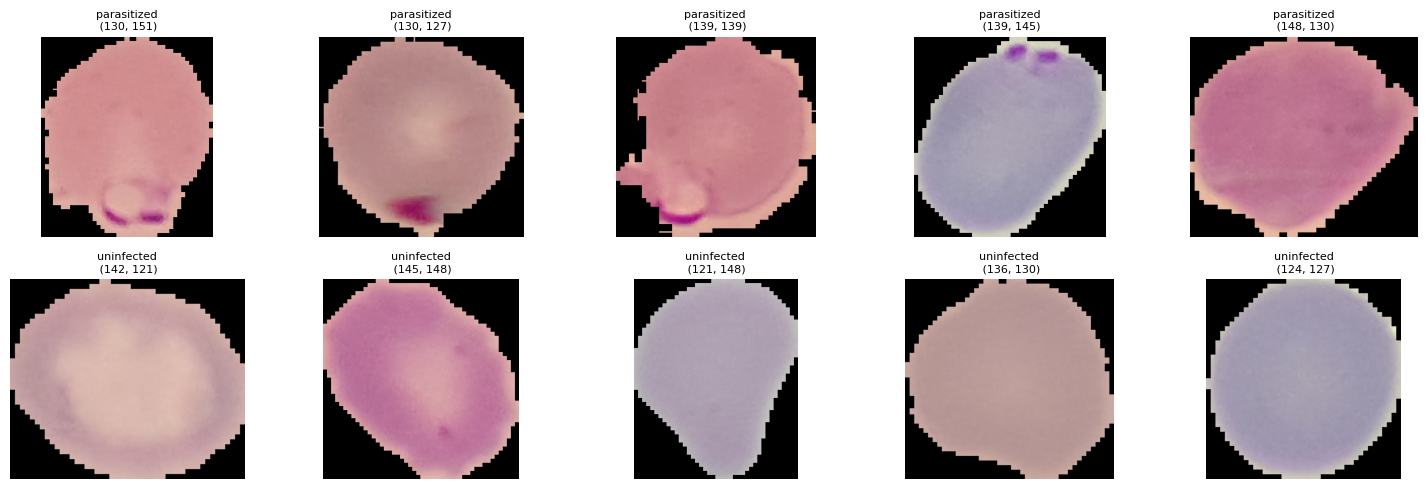

In [2]:
#cek ukuran gambar
base= '/content/data/cell_images/train'
kelas =['parasitized', 'uninfected']

#ukur gambar dari sampel acak
for k in kelas:
  files = os.listdir(f'{base}/{k}')
  sampel = random.sample(files, 300)
  ukuran = [Image.open(f'{base}/{k}/{f}').size for f in sampel]
  lebar =[u[0] for u in ukuran]
  tinggi = [u[1] for u in ukuran]
  print(k, ' | lebar min/max :', min(lebar), max(lebar), '| tinggi min/max', min(tinggi), max(tinggi))

fig, axes = plt.subplots(2, 5, figsize=(15, 5))
for i, k in enumerate(kelas):
  files = random.sample(os.listdir(f'{base}/{k}'), 5)
  for j, f in enumerate(files):
    axes[i, j].imshow(Image.open(f'{base}/{k}/{f}'))
    axes[i, j].set_title(f'{k}\n {Image.open(f"{base}/{k}/{f}").size}', fontsize=8)
    axes[i, j].axis('off')

plt.tight_layout()
plt.show()

In [3]:
#mengukur warna rata-rata sel (tanpa latar hitam) dan proporsi piksel hitam di tiap kelas
import numpy as np


for k in kelas:
  files = random.sample(os.listdir(f'{base}/{k}'), 500)
  warna, hitam = [], []
  for f in files :
    a = np.array(Image.open(f'{base}/{k}/{f}').convert('RGB'))
    sel = a.sum(axis=2)> 30  #piksel yang bukan latar hitam
    hitam.append(1 - sel.mean())
    warna.append(a[sel].mean(axis=0))
  warna = np.array(warna)
  print(k, '| R,G,B rata-rata:', warna.mean(axis=0).round(1),
          '| simpangan:', warna.std(axis=0).round(1),
          '| proporsi latar hitam:', round(np.mean(hitam), 3))

parasitized | R,G,B rata-rata: [191.6 146.5 157. ] | simpangan: [17.9 15.9 16.1] | proporsi latar hitam: 0.291
uninfected | R,G,B rata-rata: [187.4 155.7 164. ] | simpangan: [20.9 15.  17.1] | proporsi latar hitam: 0.277


Latar hitam: aman. Proporsinya 0,286 untuk terinfeksi dan 0,279 untuk sehat, hampir sama. Bentuk dan ukuran latar hitam tidak membocorkan label, jadi tidak ada masalah seperti tepi gambar di TBC.

Warna: ada selisih, tapi kecil dibanding sebaran datanya.

Merah (R) hampir sama: 190,4 vs 188,8.
Hijau (G) lebih rendah pada sel terinfeksi: 145,1 vs 157,5 (selisih 12). Biru (B) juga sedikit lebih rendah: 156,9 vs 164,9 (selisih 8).
Simpangannya sekitar 14 sampai 19, jadi selisih G hanya sekitar 0,8 simpangan. Dua kelas masih sangat tumpang tindih.

Arah selisihnya masuk akal secara biologis. Parasit memberi bercak ungu atau magenta, dan itu menurunkan hijau. Jadi sebagian selisih ini sinyal yang sah. Tapi dari angka rata-rata saja kita tidak bisa memisahkan sinyal sah itu dari perbedaan pewarnaan antar slide, jadi perlu diukur langsung

In [5]:
#mengukur seberapa jauh kita bisa menebak label hanya dari warna rata-rata

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score

X, y = [],[]
for label, k in enumerate(['uninfected', 'parasitized']):  #1:parasitized
  files = random.sample(os.listdir(f'{base}/{k}'), 2000)
  for f in files:
    a = np.array(Image.open(f'{base}/{k}/{f}').convert('RGB'))
    sel = a.sum(axis=2)>30
    X.append(a[sel].mean(axis=0))
    y.append(label)
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size =0.25, stratify=y, random_state=42)
m = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
p = m.predict(X_val)
print('acc:', accuracy_score(y_val, p), '| recall:', recall_score(y_val, p))


acc: 0.647 | recall: 0.614


Hasilnya bagus untuk kita: warna hanya petunjuk lemah. Model yang hanya melihat warna rata-rata mendapat akurasi 63,5% (tebakan acak 50%) dan recall 57,4%. Ada sinyal, tapi jauh dari cukup untuk membuat model “lulus” hanya dari warna.

Angka ini menjadi batas bawah. CNN yang hanya mencapai 65 sampai 70% berarti belum membaca bercak parasitnya. CNN yang mencapai sekitar 90% atau lebih berarti sudah membaca bentuk dan bercak di dalam sel, karena warna saja tidak bisa membawanya sejauh itu. Kita tidak perlu perlakuan khusus untuk warna.

In [6]:
''' sekarang kita ubah ukuran gambar menjadi 96x96, jika mengambil angka terkenci yaitu
64x64 bisa saja gambar ddengan bercak parasit akan terpotong serta untuk menjaga memory colab'''

import tensorflow as tf

kelas = ['uninfected', 'parasitized']      # urutan ini membuat parasitized = 1

def muat(subset):
  return tf.keras.utils.image_dataset_from_directory(
      base, class_names= kelas, label_mode = 'binary',
      image_size=(96,96), batch_size=64,
      validation_split=0.2, subset=subset, seed=42
  )

train_ds = muat('training')
val_ds = muat('validation')

for x, y in train_ds.take(1):
    print('bentuk gambar:', x.shape, '| bentuk label:', y.shape)
    print('nilai piksel min/maks:', x.numpy().min(), x.numpy().max())
    print('jumlah parasitized di batch ini:', int(y.numpy().sum()), 'dari', len(y))

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds   = val_ds.prefetch(tf.data.AUTOTUNE)


Found 24958 files belonging to 2 classes.
Using 19967 files for training.
Found 24958 files belonging to 2 classes.
Using 4991 files for validation.
bentuk gambar: (64, 96, 96, 3) | bentuk label: (64, 1)
nilai piksel min/maks: 0.0 239.36458
jumlah parasitized di batch ini: 28 dari 64


Kode diatas menyiapkan data dalam bentuk yang bisa langsung dibaca model. Cetakannya untuk memastikan tiga hal: gambar berbentuk (64, 96, 96, 3), label berisi 0 dan 1 dengan jumlah parasitized masuk akal (sekitar setengah batch), dan piksel masih di rentang 0 sampai 255.

**CNN pertama **

dengan arsitektur:
Rescaling 1/255 mengubah piksel ke rentang 0 sampai 1, karena jaringan belajar lebih stabil dengan angka kecil.
Tiga blok Conv2D + MaxPooling (16, 32, 64 filter). Blok awal menangkap pola sederhana seperti tepi dan warna. Blok yang lebih dalam menggabungkannya menjadi pola yang lebih rumit seperti bercak ungu. MaxPooling mengecilkan gambar sambil menyimpan respons terkuat.
GlobalAveragePooling merangkum tiap filter menjadi satu angka, jadi model tetap kecil (sekitar 25 ribu parameter) dan tidak mudah menghafal.
Dense 32 + Dropout 0,3 + Dense 1 (sigmoid). Dropout mematikan sebagian neuron secara acak saat training supaya tidak overfit. Neuron akhir menghasilkan probabilitas parasitized.


In [7]:
#CNN awal
import keras
from keras import layers

model = keras.Sequential([
    layers.Input(shape=(96,96,3)),
    layers.Rescaling(1/255),
    layers.Conv2D(16,3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer ='adam', loss='binary_crossentropy',
              metrics=['accuracy', keras.metrics.Recall(name='recall'),
                       keras.metrics.AUC(name= 'auc')])
model.summary()

folder = '/content/drive/MyDrive/malaria-dataset'
callbacks =[
    keras.callbacks.ModelCheckpoint(f'{folder}/cnn_malaria_1.keras', monitor='val_loss', save_best_only=True),
    keras.callbacks.CSVLogger(f'{folder}/cnn_malaria_1_history.csv'),
]

hasil = model.fit(train_ds, validation_data = val_ds, epochs=15, callbacks=callbacks)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 94, 94, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,697 (100.38 KB)

 Trainable params: 25,697 (100.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
312/312 ━━━━━━━━━━━━━━━━━━━━ 33s 76ms/step - accuracy: 0.6345 - auc: 0.6912 - loss: 0.6390 - recall: 0.5792 - val_accuracy: 0.8145 - val_auc: 0.8873 - val_loss: 0.5475 - val_recall: 0.9152
Epoch 2/15
312/312 ━━━━━━━━━━━━━━━━━━━━ 17s 54ms/step - accuracy: 0.8791 - auc: 0.9255 - loss: 0.3682 - recall: 0.8345 - val_accuracy: 0.9090 - val_auc: 0.9588 - val_loss: 0.2701 - val_recall: 0.9049
Epoch 3/15
312/312 ━━━━━━━━━━━━━━━━━━━━ 17s 54ms/step - accuracy: 0.9242 - auc: 0.9553 - loss: 0.2569 - recall: 0.8956 - val_accuracy: 0.9152 - val_auc: 0.9720 - val_loss: 0.2285 - val_recall: 0.9124
Epoch 4/15
312/312 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - accuracy: 0.9312 - auc: 0.9633 - loss: 0.2269 - recall: 0.9080 - val_accuracy: 0.9307 - val_auc: 0.9803 - val_loss: 0.1976 - val_recall: 0.9365
Epoch 5/15
312/312 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step - accuracy: 0.9382 - auc: 0.9714 - loss: 0.1982 - recall: 0.9216 - val_accuracy: 0.9399 - val_auc: 0.9833 - val_loss: 0.1718 - val_recall: 0.9081


1. Model benar-benar membaca bercak parasit. Model hanya dengan warna rata-rata menghasilkan akurasi 0,635, sedangkan CNN ini mencapai val_acc 0,956, val_recall 0,946, dan val_auc 0,988 dengan hanya 25.697 parameter. Selisih sebesar itu tidak bisa dijelaskan oleh warna. Latar hitam juga sudah kita periksa dan hasilnya aman.

2. Tidak ada overfitting. Akurasi train (0,956) dan val (0,956) hampir sama, bahkan loss val (0,137) sedikit di bawah loss train (0,140). Itu wajar, karena Dropout aktif saat training tapi mati saat validasi. Artinya model belum menghafal, dan kalau ada masalah, justru kapasitasnya yang masih kecil. Setelah epoch 9 kenaikannya sudah melambat, jadi training lebih lama dengan model yang sama tidak akan menambah banyak.

3. Recall 0,946 berarti sekitar 5 dari 100 sel terinfeksi lolos. Dalam konteks medis, kasus terlewat lebih berbahaya daripada alarm palsu. Seperti di TBC, kita bisa menggeser garis pemisah dari 0,5 ke angka yang lebih rendah, dan harganya adalah lebih banyak sel sehat yang dicurigai.

Catatan jujur. Angka val ini belum bisa dibandingkan langsung dengan hasil test. Pembagian val diacak per gambar, jadi sel dari pasien yang sama bisa ada di train dan val, dan angka bisa sedikit terlalu bagus. Kebocoran ini mungkin juga ada di folder test. Jadi hasil akhir nanti tetap kita tulis sebagai batas atas, bukan klaim performa klinis.

garis 0.5: TN 2377, FP 79, FN 129, TP 2406 | recall 0.949, spesifisitas 0.968


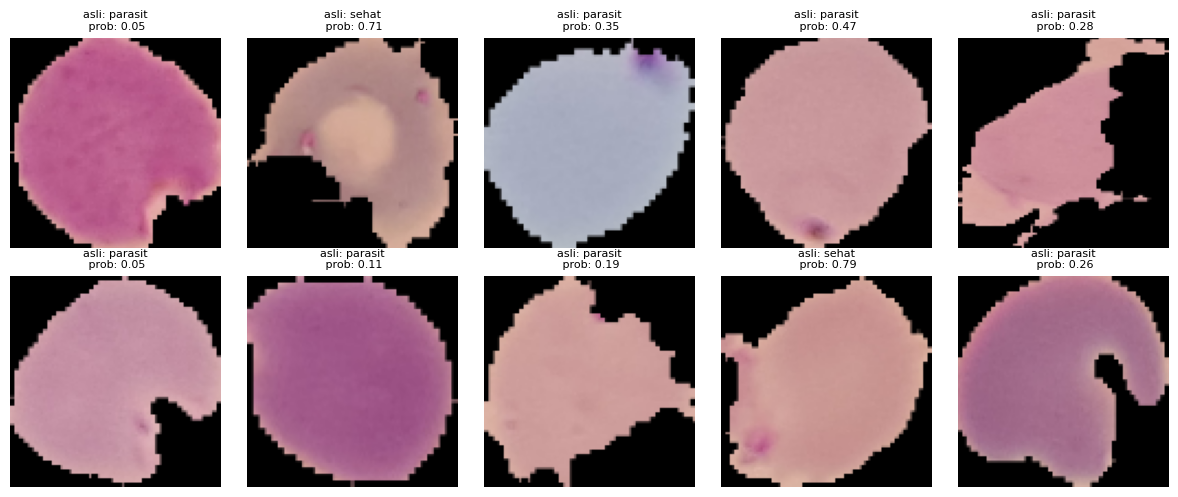

garis 0.3: TN 2312, FP 144, FN 95, TP 2440 | recall 0.963, spesifisitas 0.941


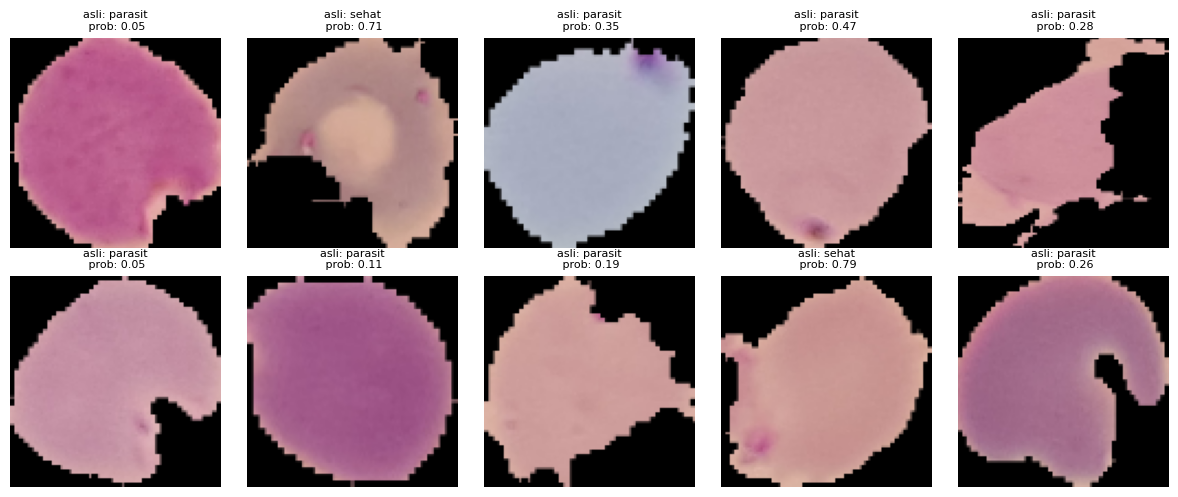

In [8]:
#confusion matrix dan gambar yang salah

from sklearn.metrics import confusion_matrix

best = keras.models.load_model('/content/drive/MyDrive/malaria-dataset/cnn_malaria_1.keras')

y_true, y_prob, salah = [],[],[]

for x, y in val_ds:
  p= best.predict(x, verbose=0).ravel()
  y_true.extend(y.numpy().ravel()); y_prob.extend(p)
  for img, yt, pp in zip(x.numpy(), y.numpy().ravel(), p):
    if (pp >=0.5) != (yt ==1) and len(salah)<10:
      salah.append((img,int(yt), pp))

y_true, y_prob = np.array(y_true), np.array(y_prob)

for garis in [0.5, 0.3]:
  pred = (y_prob >= garis).astype(int)
  tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
  print(f'garis {garis}: TN {tn}, FP {fp}, FN {fn}, TP {tp} | '
          f'recall {tp/(tp+fn):.3f}, spesifisitas {tn/(tn+fp):.3f}')

  fig, axes = plt.subplots(2, 5, figsize = (12, 5))
  for ax, (img, yt, pp) in zip(axes.ravel(), salah):
    ax.imshow(img.astype('uint8'))
    ax.set_title(f'asli: {'parasit' if yt else 'sehat'}\n prob: {pp:.2f}', fontsize=8)
    ax.axis('off')

  plt.tight_layout()
  plt.show()


Garis pemisah: lebih banyak alarm palsu untuk sedikit kasus yang tertangkap.

Garis	Sel terinfeksi lolos (FN)	Alarm palsu (FP)	Recall	Spesifisitas

0,5	131	91	0,948	0,963

0,3	90	233	0,964	0,905

Menurunkan garis ke 0,3 menangkap 41 sel terinfeksi tambahan, tapi harganya 142 alarm palsu tambahan. Artinya setiap satu kasus yang tertangkap, kita menambah sekitar 3,5 sel sehat yang dicurigai. Seperti di TBC, kita lebih menerima alarm palsu daripada kasus yang lolos, tapi di sini harganya cukup mahal. Garis 0,4 bisa jadi jalan tengah. Kita putuskan nanti setelah model kedua selesai, dan hanya berdasarkan data validasi, bukan test.

Tujuannya bukan mengejar angka setinggi mungkin, tapi melihat apakah model lebih kuat lewat dua perubahan yang masuk akal:

Augmentasi: gambar dibalik dan diputar secara acak saat training. Sel darah tidak punya “atas” dan “bawah”, jadi orientasi tidak seharusnya mempengaruhi label. Rotasi diisi hitam (fill_mode='constant') supaya latar tetap hitam seperti data asli, tidak memantulkan sel. Kecerahan juga diacak sedikit supaya model tidak mengandalkan intensitas warna. Lapisan ini hanya aktif saat training, jadi validasi dan test tetap memakai gambar asli.
Model lebih besar: filter dinaikkan menjadi 32/64/128 dan Dense menjadi 64, karena model pertama tidak overfit dan masih punya ruang untuk belajar lebih banyak.
python

In [9]:
#CNN kedua dengan augmentasi.

model2 = keras.Sequential([
    layers.Input(shape=(96, 96, 3)),
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.25, fill_mode='constant', fill_value=0.0),
    layers.RandomBrightness(0.1, value_range=(0, 255)),
    layers.Rescaling(1/255),
    layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'), layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid'),
])

model2.compile(optimizer='adam', loss='binary_crossentropy',
               metrics=['accuracy',
                        keras.metrics.Recall(name='recall'),
                        keras.metrics.AUC(name='auc')])
model2.summary()

folder = '/content/drive/MyDrive/malaria-dataset'
callbacks = [
    keras.callbacks.ModelCheckpoint(f'{folder}/cnn_malaria_2.keras',
                                    monitor='val_loss', save_best_only=True),
    keras.callbacks.CSVLogger(f'{folder}/cnn_malaria_2_history.csv'),
]

model2.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 96, 96, 3)      │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 29s 63ms/step - accuracy: 0.7530 - auc: 0.8386 - loss: 0.5161 - recall: 0.6985 - val_accuracy: 0.8916 - val_auc: 0.9623 - val_loss: 0.2968 - val_recall: 0.8296
Epoch 2/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - accuracy: 0.9165 - auc: 0.9503 - loss: 0.2652 - recall: 0.8896 - val_accuracy: 0.9187 - val_auc: 0.9786 - val_loss: 0.2252 - val_recall: 0.9460
Epoch 3/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - accuracy: 0.9253 - auc: 0.9655 - loss: 0.2191 - recall: 0.9186 - val_accuracy: 0.9327 - val_auc: 0.9786 - val_loss: 0.1985 - val_recall: 0.9168
Epoch 4/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 16s 51ms/step - accuracy: 0.9357 - auc: 0.9724 - loss: 0.1921 - recall: 0.9316 - val_accuracy: 0.9369 - val_auc: 0.9849 - val_loss: 0.1773 - val_recall: 0.9598
Epoch 5/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 16s 51ms/step - accuracy: 0.9415 - auc: 0.9753 - loss: 0.1830 - recall: 0.9334 - val_accuracy: 0.9525 - val_auc: 0.9863 - val_loss: 0.1516 - val_recall: 0.9448


Selisih akurasi (0,3 poin) masih dalam noise. Dengan 4.991 gambar validasi, angka akurasi bisa bergeser sekitar 0,3 poin hanya karena kebetulan. Lihat juga epoch 12: val_acc tiba-tiba turun ke 0,9365 lalu pulih. Jadi jangan menilai dari satu epoch.
Val_loss dan AUC lebih meyakinkan. Val_loss turun dari 0,1346 ke 0,1188 dan AUC naik dari 0,988 ke 0,991. Keduanya konsisten membaik di banyak epoch, jadi CNN kedua memang sedikit lebih baik dalam memisahkan dua kelas.
Tidak overfit. Akurasi train (0,955) dan val (0,959) hampir sama.
Kita sudah dekat batas atasnya. Menambah ukuran model 4 kali lipat dan memberi augmentasi hanya menambah sekitar 0,3 poin. Itu tanda bahwa batasnya bukan di model, melainkan di data: label yang meragukan, seperti sel tanpa bercak yang berlabel parasit tadi. Menambah epoch atau lapisan lagi kemungkinan hanya menambah sedikit.

In [10]:
#menentukan garis pemisah dari data validasi

best = keras.models.load_model('/content/drive/MyDrive/malaria-dataset/cnn_malaria_2.keras')
y_true, y_prob = [],[]
for x, y in val_ds:
  y_prob.extend(best.predict(x, verbose=0).ravel())
  y_true.extend(y.numpy().ravel())
y_true, y_prob = np.array(y_true), np.array(y_prob)


print('garis | FN  | FP  | recall | spesifisitas | presisi')
for garis in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pred = (y_prob >= garis).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    print(f'{garis:.1f}   | {fn:3d} | {fp:3d} | {tp/(tp+fn):.3f}  | '
          f'{tn/(tn+fp):.3f}        | {tp/(tp+fp):.3f}')


garis | FN  | FP  | recall | spesifisitas | presisi
0.2   |  74 | 167 | 0.971  | 0.932        | 0.936
0.3   |  93 | 125 | 0.963  | 0.949        | 0.951
0.4   | 107 |  99 | 0.958  | 0.960        | 0.961
0.5   | 124 |  83 | 0.951  | 0.966        | 0.967
0.6   | 141 |  69 | 0.944  | 0.972        | 0.972


Jumlah sel terinfeksi yang lolos hampir sama, tapi alarm palsu CNN kedua jauh lebih sedikit. Di garis 0,3 alarm palsunya turun dari 233 ke 130, di garis 0,2 dari 347 ke 177. Inilah manfaat nyata model kedua. Akurasi pada garis 0,5 hampir tidak berubah, jadi kelebihannya baru terlihat saat kita menurunkan garis.

In [11]:
from sklearn.metrics import roc_auc_score
GARIS = 0.3     # ganti sebelum menjalankan kalau kamu memilih garis lain

best = keras.models.load_model('/content/drive/MyDrive/malaria-dataset/cnn_malaria_2.keras')
assert best.count_params() == 101569, 'ini bukan model kedua!'

test_ds = keras.utils.image_dataset_from_directory(
    '/content/data/cell_images/test',
    class_names=['uninfected', 'parasitized'], label_mode='binary',
    image_size=(96, 96), batch_size=64, shuffle=False)

y_true, y_prob = [], []
for x, y in test_ds:
    y_prob.extend(best.predict(x, verbose=0).ravel())
    y_true.extend(y.numpy().ravel())
y_true, y_prob = np.array(y_true), np.array(y_prob)

pred = (y_prob >= GARIS).astype(int)
tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
print(f'garis {GARIS}: TN {tn}, FP {fp}, FN {fn}, TP {tp}')
print(f'recall {tp/(tp+fn):.3f} | spesifisitas {tn/(tn+fp):.3f} | '
      f'presisi {tp/(tp+fp):.3f} | akurasi {(tp+tn)/len(y_true):.3f} | '
      f'AUC {roc_auc_score(y_true, y_prob):.3f}')

Found 2600 files belonging to 2 classes.
garis 0.3: TN 1227, FP 73, FN 54, TP 1246
recall 0.958 | spesifisitas 0.944 | presisi 0.945 | akurasi 0.951 | AUC 0.990


Secara praktis, dari 1.300 sel terinfeksi ada 55 yang lolos (4,2%), dan dari 1.300 sel sehat ada 71 yang dicurigai (5,5%). Dengan ukuran test sebesar ini, rentang ketidakpastiannya sekitar ±1 poin, jadi recall sebenarnya wajar berada di sekitar 0,947 sampai 0,969.

**Grand-CAM**

In [16]:
from keras import layers

best = keras.models.load_model('/content/drive/MyDrive/malaria-dataset/cnn_malaria_2.keras')
conv_terakhir = [l for l in best.layers if isinstance(l, layers.Conv2D)][-1]
print('layer conv terakhir:', conv_terakhir.name)

# Susun ulang jalur: gambar -> semua lapisan berurutan, dan catat keluaran conv terakhir
masuk = keras.Input(shape=(96, 96, 3))
h = masuk
for l in best.layers:
    if l.__class__.__name__.startswith('Random'):   # augmentasi hanya untuk training, lewati
        continue
    h = l(h)
    if l is conv_terakhir:
        peta_ciri = h
grad_model = keras.Model(masuk, [peta_ciri, h])

test_ds = keras.utils.image_dataset_from_directory(
    '/content/data/cell_images/test', class_names=['uninfected', 'parasitized'],
    label_mode='binary', image_size=(96, 96), batch_size=8, shuffle=True, seed=1)
x, y = next(iter(test_ds))

peta, prob = grad_model(x[:1])
print('bentuk keluaran conv terakhir:', peta.shape)
print('probabilitas parasitized:', float(prob[0, 0]), '| label asli:', int(y[0, 0]))

layer conv terakhir: conv2d_5
Found 2600 files belonging to 2 classes.
bentuk keluaran conv terakhir: (1, 20, 20, 128)
probabilitas parasitized: 0.014898300170898438 | label asli: 0


In [17]:
#deteksi bobot gradien
import tensorflow as tf

# Ambil satu sel berlabel parasitized dari batch
i = int(np.argmax(y.numpy().ravel()))
gambar = x[i:i+1]
print('label asli:', int(y[i, 0]))

with tf.GradientTape() as tape:
    peta, prob = grad_model(gambar)
    skor = prob[:, 0]                      # skor parasitized
print('probabilitas parasitized:', float(skor[0]))

gradien = tape.gradient(skor, peta)         # pengaruh tiap angka di peta terhadap skor
print('bentuk gradien:', gradien.shape)

bobot = tf.reduce_mean(gradien, axis=(0, 1, 2))   # rata-rata per pendeteksi
print('bentuk bobot:', bobot.shape)
print('bobot terbesar:', float(tf.reduce_max(bobot)),
      '| terkecil:', float(tf.reduce_min(bobot)))

label asli: 1
probabilitas parasitized: 0.9991258978843689
bentuk gradien: (1, 20, 20, 128)
bentuk bobot: (128,)
bobot terbesar: 6.458693405875238e-06 | terkecil: -3.8081757338659372e-06


GradientTape mencatat perhitungan model supaya kita bisa menanyakan “seberapa berpengaruh peta ini terhadap skor?”. Baris reduce_mean mengubah gradien 20×20 per pendeteksi menjadi satu angka bobot. Kalau batch ini kebetulan tidak punya sel parasitized, label asli yang tercetak akan 0. Dalam kasus itu, jalankan ulang sel test_ds di langkah sebelumnya (ganti seed=1 ke angka lain), lalu jalankan sel ini lagi.

bentuk peta panas: (20, 20) | min/maks: 0.0 0.999947190284729


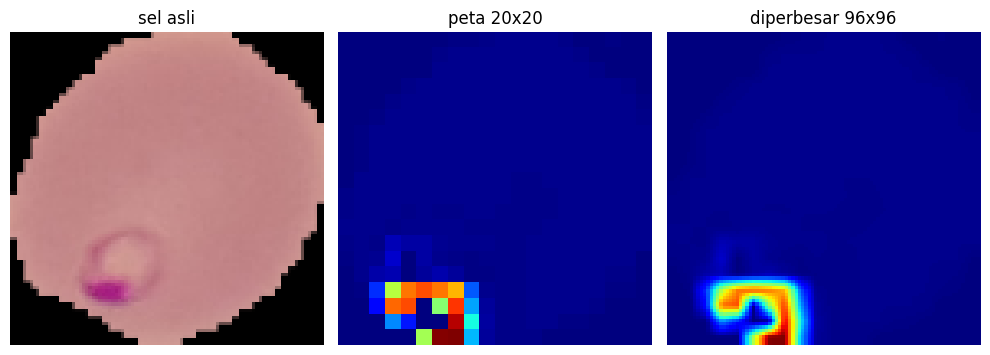

In [18]:
peta_ciri = peta[0]                                    # bentuk (20, 20, 128)
heat = tf.reduce_sum(peta_ciri * bobot, axis=-1)       # jumlahkan 128 peta berbobot -> (20, 20)
heat = tf.nn.relu(heat)                                # buang bukti yang berlawanan arah
heat = heat / (tf.reduce_max(heat) + 1e-8)             # normalkan ke 0..1
print('bentuk peta panas:', heat.shape,
      '| min/maks:', float(tf.reduce_min(heat)), float(tf.reduce_max(heat)))

heat_besar = tf.image.resize(heat[..., None], (96, 96))[..., 0].numpy()

fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
ax[0].imshow(gambar[0].numpy().astype('uint8')); ax[0].set_title('sel asli')
ax[1].imshow(heat.numpy(), cmap='jet');          ax[1].set_title('peta 20x20')
ax[2].imshow(heat_besar, cmap='jet');            ax[2].set_title('diperbesar 96x96')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

Found 2600 files belonging to 2 classes.


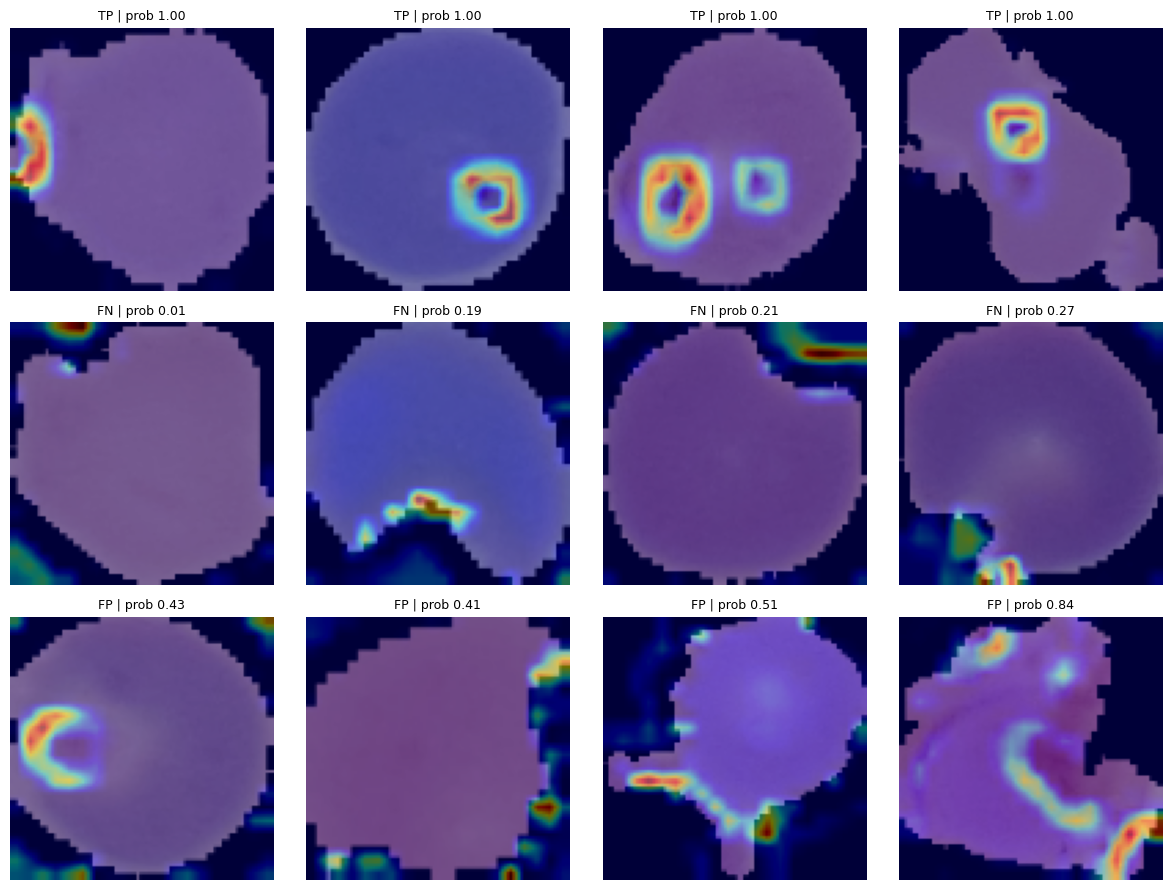

In [19]:
def gradcam(gambar):                      # gambar: bentuk (1, 96, 96, 3)
    with tf.GradientTape() as tape:
        peta, prob = grad_model(gambar)
        skor = prob[:, 0]
    g = tape.gradient(skor, peta)
    w = tf.reduce_mean(g, axis=(0, 1, 2))                  # bobot tiap pendeteksi
    h = tf.nn.relu(tf.reduce_sum(peta[0] * w, axis=-1))    # gabungkan, buang yang negatif
    h = h / (tf.reduce_max(h) + 1e-8)                      # normalkan 0..1
    return tf.image.resize(h[..., None], (96, 96))[..., 0].numpy()

# Kumpulkan 4 contoh per kelompok dari data test (garis 0,3)
test_ds2 = keras.utils.image_dataset_from_directory(
    '/content/data/cell_images/test', class_names=['uninfected', 'parasitized'],
    label_mode='binary', image_size=(96, 96), batch_size=64, shuffle=True, seed=3)

grup = {'TP': [], 'FN': [], 'FP': []}
for xb, yb in test_ds2:
    pb = best.predict(xb, verbose=0).ravel()
    for img, yt, p in zip(xb.numpy(), yb.numpy().ravel(), pb):
        if p >= 0.3 and yt == 1:   k = 'TP'
        elif p < 0.3 and yt == 1:  k = 'FN'
        elif p >= 0.3 and yt == 0: k = 'FP'
        else: continue
        if len(grup[k]) < 4:
            grup[k].append((img, p))
    if all(len(v) == 4 for v in grup.values()):
        break

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for baris, k in enumerate(['TP', 'FN', 'FP']):
    for kol, (img, p) in enumerate(grup[k]):
        heat = gradcam(img[None, ...])
        ax = axes[baris, kol]
        ax.imshow(img.astype('uint8'))
        ax.imshow(heat, cmap='jet', alpha=0.45)
        ax.set_title(f'{k} | prob {p:.2f}', fontsize=9)
        ax.axis('off')
plt.tight_layout(); plt.show()

Baris TP (benar mendeteksi parasit, prob 1,00). Area merah jatuh pada struktur berbentuk cincin atau bulan sabit di dalam sel. Sel ketiga bahkan punya dua cincin dan keduanya menyala. Model memang mencari bentuk parasit. Hanya sel paling kiri yang hot spot-nya menempel di tepi sel. Bentuknya tetap mirip cincin, tapi posisi di tepi membuatnya paling sulit dipastikan.

Baris FN (parasit yang lolos, prob 0,01 sampai 0,27). Sel-selnya tampak polos tanpa cincin jelas, dan area panasnya hanya titik-titik kecil di tepi atau di luar sel. Artinya model tidak menemukan struktur parasit di dalam sel. Bisa jadi parasit tidak terlihat di potongan ini, atau labelnya yang meragukan seperti yang kita curigai sebelumnya. Sel kedua (prob 0,19) punya hot spot di ujung bawah sel, mungkin parasit kecil di pinggir yang setengah terdeteksi.

Baris FP (sehat yang dicurigai, prob 0,41 sampai 0,84). Ada dua jenis:

Sel pertama (0,43) punya bentuk bulan sabit yang jelas, mirip parasit. Ini mungkin label yang keliru atau struktur serupa yang memang menipu.
Sel kedua sampai keempat berbentuk tidak beraturan (terlipat, bergerigi, tepinya berlekuk), dengan panas di tepi sel. Sel keempat, prob 0,84, tampak seperti sel kusut yang tepinya membentuk lekukan menyerupai bulan sabit.

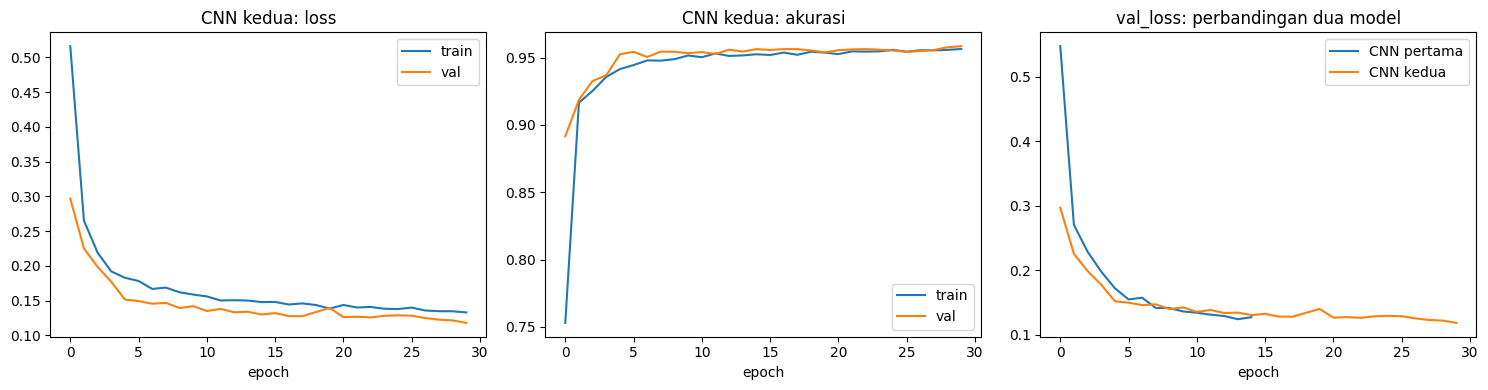

In [21]:
import pandas as pd
folder = '/content/drive/MyDrive/malaria-dataset'
fig_dir = f'{folder}/figures'
os.makedirs(fig_dir, exist_ok=True)

h1 = pd.read_csv(f'{folder}/cnn_malaria_1_history.csv')
h2 = pd.read_csv(f'{folder}/cnn_malaria_2_history.csv')

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(h2['loss'], label='train'); ax[0].plot(h2['val_loss'], label='val')
ax[0].set_title('CNN kedua: loss')
ax[1].plot(h2['accuracy'], label='train'); ax[1].plot(h2['val_accuracy'], label='val')
ax[1].set_title('CNN kedua: akurasi')
ax[2].plot(h1['val_loss'], label='CNN pertama'); ax[2].plot(h2['val_loss'], label='CNN kedua')
ax[2].set_title('val_loss: perbandingan dua model')
for a in ax:
    a.set_xlabel('epoch'); a.legend()
plt.tight_layout()
plt.savefig(f'{fig_dir}/kurva_training.png', dpi=150, bbox_inches='tight')
plt.show()

Found 2600 files belonging to 2 classes.


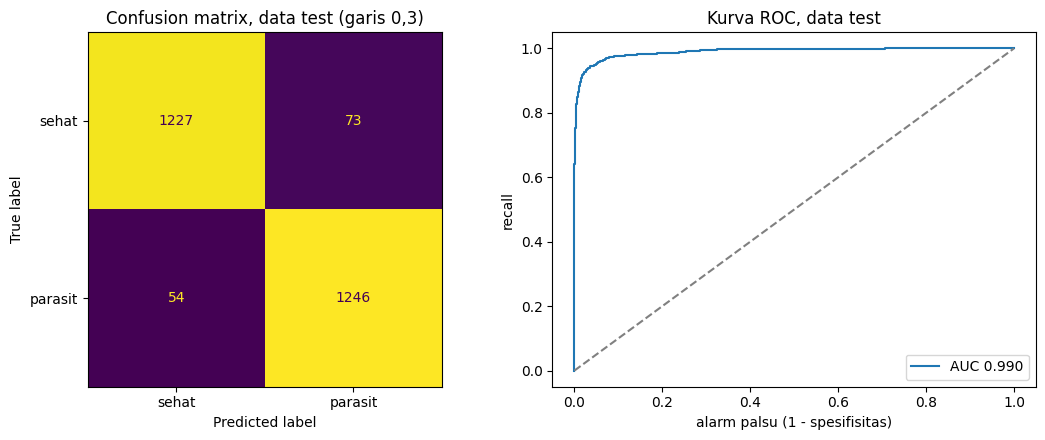

In [22]:
import numpy as np, keras
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

best = keras.models.load_model(f'{folder}/cnn_malaria_2.keras')
assert best.count_params() == 101569, 'ini bukan model kedua!'

test_ds = keras.utils.image_dataset_from_directory(
    '/content/data/cell_images/test', class_names=['uninfected', 'parasitized'],
    label_mode='binary', image_size=(96, 96), batch_size=64, shuffle=False)

y_true, y_prob = [], []
for x, y in test_ds:
    y_prob.extend(best.predict(x, verbose=0).ravel())
    y_true.extend(y.numpy().ravel())
y_true, y_prob = np.array(y_true), np.array(y_prob)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
cm = confusion_matrix(y_true, (y_prob >= 0.3).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['sehat', 'parasit']).plot(ax=ax[0], colorbar=False)
ax[0].set_title('Confusion matrix, data test (garis 0,3)')

fpr, tpr, _ = roc_curve(y_true, y_prob)
ax[1].plot(fpr, tpr, label=f'AUC {roc_auc_score(y_true, y_prob):.3f}')
ax[1].plot([0, 1], [0, 1], '--', color='gray')
ax[1].set_xlabel('alarm palsu (1 - spesifisitas)'); ax[1].set_ylabel('recall')
ax[1].set_title('Kurva ROC, data test'); ax[1].legend()
plt.tight_layout()
plt.savefig(f'{fig_dir}/confusion_roc_test.png', dpi=150, bbox_inches='tight')
plt.show()

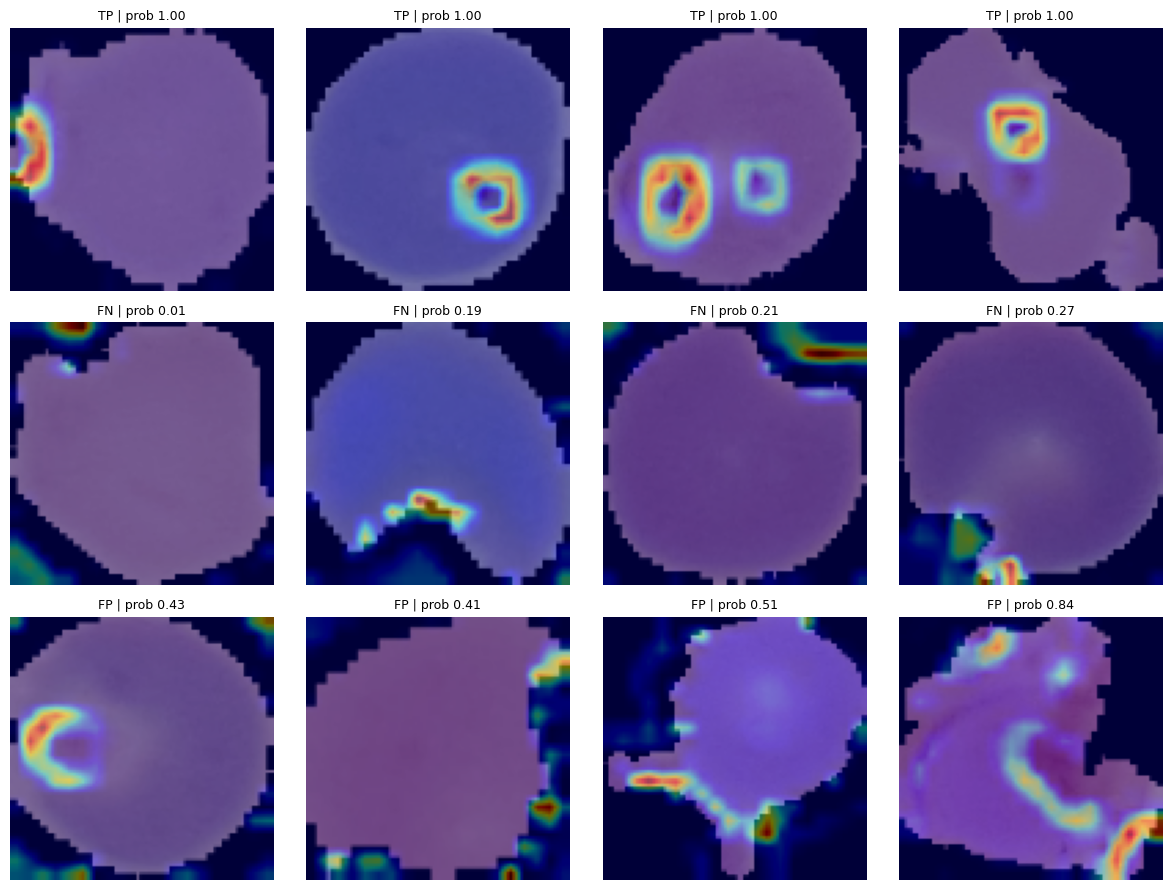

['kurva_training.png', 'confusion_roc_test.png', 'gradcam_grid.png']


In [23]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for baris, k in enumerate(['TP', 'FN', 'FP']):
    for kol, (img, p) in enumerate(grup[k]):
        heat = gradcam(img[None, ...])
        ax = axes[baris, kol]
        ax.imshow(img.astype('uint8'))
        ax.imshow(heat, cmap='jet', alpha=0.45)
        ax.set_title(f'{k} | prob {p:.2f}', fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.savefig(f'{fig_dir}/gradcam_grid.png', dpi=150, bbox_inches='tight')
plt.show()

print(os.listdir(fig_dir))